In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# 1. Load the dataset
file_path = "/home/daniella/code/DataAnalytics-2026/Week_4/DA2026W4D1/US_Superstore_data.xls"
df = pd.read_excel(file_path)

# 2. Inspect structure and missing values
print("Missing values per column:\n", df.isnull().sum()[df.isnull().sum() > 0])
print("\nInitial Data Types:\n", df[['Order Date', 'Ship Date', 'Sales', 'Profit', 'Discount']].dtypes)

# 3. Handle duplicates and missing values
df.drop_duplicates(inplace=True)
# Postal Code occasionally has missing values in Superstore datasets; fill or drop if needed
if 'Postal Code' in df.columns:
    df['Postal Code'] = df['Postal Code'].fillna(0).astype(int)

# 4. Convert date columns to datetime and extract Year
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])
df['Year'] = df['Order Date'].dt.year

print("\nCleaned Dataset Shape:", df.shape)


Missing values per column:
 Series([], dtype: int64)

Initial Data Types:
 Order Date    datetime64[us]
Ship Date     datetime64[us]
Sales                float64
Profit               float64
Discount             float64
dtype: object

Cleaned Dataset Shape: (9994, 22)


/tmp/ipykernel_102824/2916769469.py:16: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)


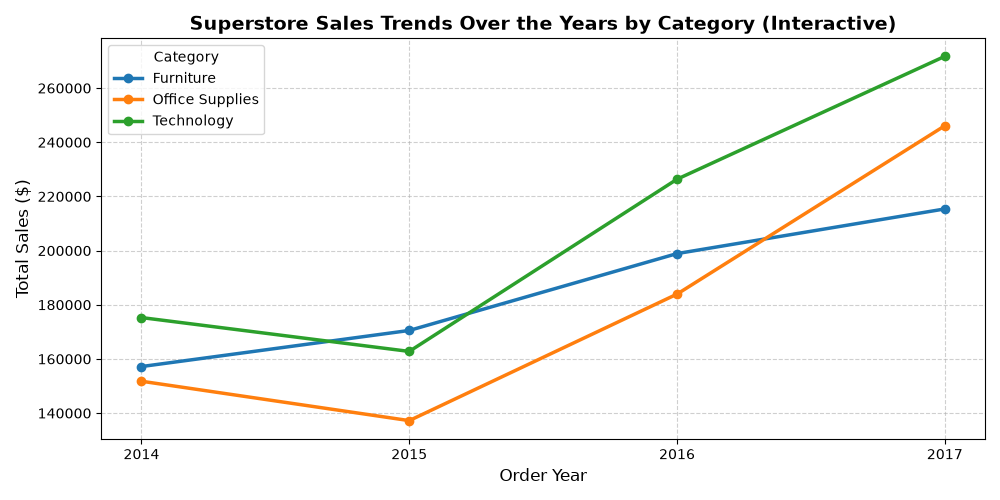

In [ ]:

sales_by_year = df.groupby(['Year', 'Category'])['Sales'].sum().unstack()

fig, ax = plt.subplots(figsize=(10, 5))

for category in sales_by_year.columns:
    ax.plot(
        sales_by_year.index, 
        sales_by_year[category], 
        marker='o', 
        linewidth=2.5, 
        label=category
    )

# Formatting
ax.set_title('Superstore Sales Trends Over the Years by Category (Interactive)', fontsize=14, fontweight='bold')
ax.set_xlabel('Order Year', fontsize=12)
ax.set_ylabel('Total Sales ($)', fontsize=12)
ax.set_xticks(sales_by_year.index) # Ensure clean integer years
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(title='Category')

# Optional: Add hover annotations if mplcursors is installed (pip install mplcursors)
try:
    import mplcursors
    cursor = mplcursors.cursor(hover=True)
    @cursor.connect("add")
    def on_add(sel):
        sel.annotation.set_text(f"Year: {int(sel.target[0])}\nSales: ${sel.target[1]:,.2f}")
except ImportError:
    pass

plt.tight_layout()
plt.show()


In [6]:
# Aggregate sales by Country
sales_by_country = df.groupby('Country', as_index=False)['Sales'].sum()

fig_country = px.choropleth(
    sales_by_country,
    locations='Country',
    locationmode='country names',
    color='Sales',
    hover_name='Country',
    color_continuous_scale='Blues',
    title='Total Sales Distribution by Country'
)
fig_country.update_traces(hovertemplate='<b>%{hovertext}</b><br>Total Sales: $%{z:,.2f}<extra></extra>')
fig_country.show()

# Bonus/Granular View: State-level map (since US Superstore only covers the United States)
us_state_abbrev = {
    'Alabama': 'AL', 'Alaska': 'AK', 'Arizona': 'AZ', 'Arkansas': 'AR', 'California': 'CA',
    'Colorado': 'CO', 'Connecticut': 'CT', 'Delaware': 'DE', 'District of Columbia': 'DC',
    'Florida': 'FL', 'Georgia': 'GA', 'Hawaii': 'HI', 'Idaho': 'ID', 'Illinois': 'IL',
    'Indiana': 'IN', 'Iowa': 'IA', 'Kansas': 'KS', 'Kentucky': 'KY', 'Louisiana': 'LA',
    'Maine': 'ME', 'Maryland': 'MD', 'Massachusetts': 'MA', 'Michigan': 'MI', 'Minnesota': 'MN',
    'Mississippi': 'MS', 'Missouri': 'MO', 'Montana': 'MT', 'Nebraska': 'NE', 'Nevada': 'NV',
    'New Hampshire': 'NH', 'New Jersey': 'NJ', 'New Mexico': 'NM', 'New York': 'NY',
    'North Carolina': 'NC', 'North Dakota': 'ND', 'Ohio': 'OH', 'Oklahoma': 'OK', 'Oregon': 'OR',
    'Pennsylvania': 'PA', 'Rhode Island': 'RI', 'South Carolina': 'SC', 'South Dakota': 'SD',
    'Tennessee': 'TN', 'Texas': 'TX', 'Utah': 'UT', 'Vermont': 'VT', 'Virginia': 'VA',
    'Washington': 'WA', 'West Virginia': 'WV', 'Wisconsin': 'WI', 'Wyoming': 'WY'
}
df['State Code'] = df['State'].map(us_state_abbrev)
sales_by_state = df.groupby(['State', 'State Code'], as_index=False)['Sales'].sum()

fig_state = px.choropleth(
    sales_by_state,
    locations='State Code',
    locationmode='USA-states',
    color='Sales',
    scope='usa',
    hover_name='State',
    color_continuous_scale='Viridis',
    title='Regional Sales Distribution Across US States'
)
fig_state.show()


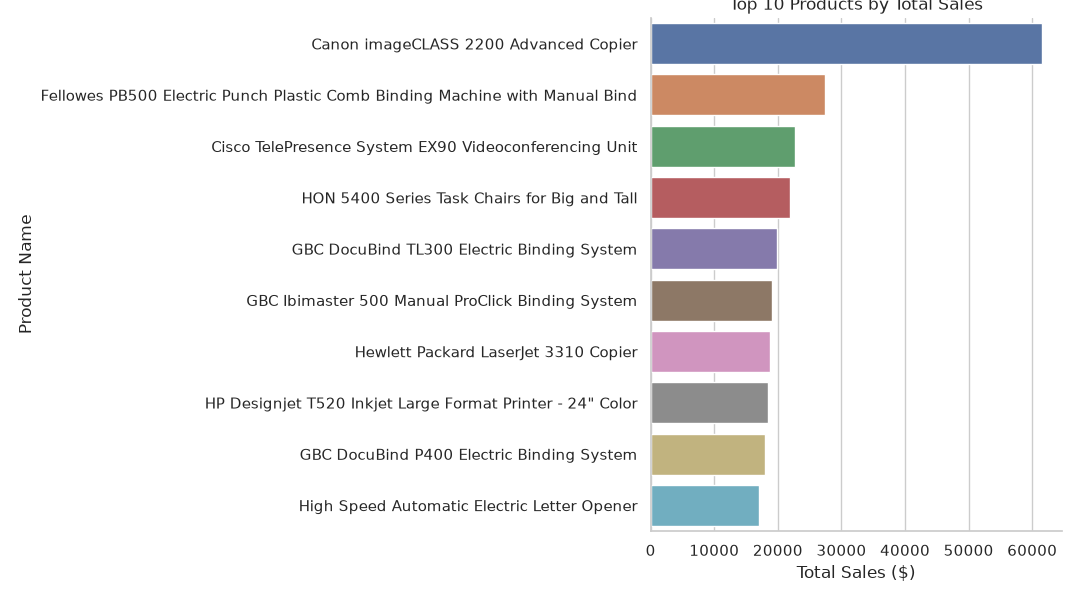

In [8]:
top_10_products = (
    df.groupby('Product Name', as_index=False)['Sales']
    .sum()
    .sort_values(by='Sales', ascending=False)
    .head(10)
)

sns.set_theme(style='whitegrid')

bar_chart = sns.catplot(
    data=top_10_products,
    x='Sales',
    y='Product Name',
    hue='Product Name',
    kind='bar',
    legend=False,
    height=6,
    aspect=1.8
)

bar_chart.set(
    title='Top 10 Products by Total Sales',
    xlabel='Total Sales ($)',
    ylabel='Product Name'
)
plt.show()


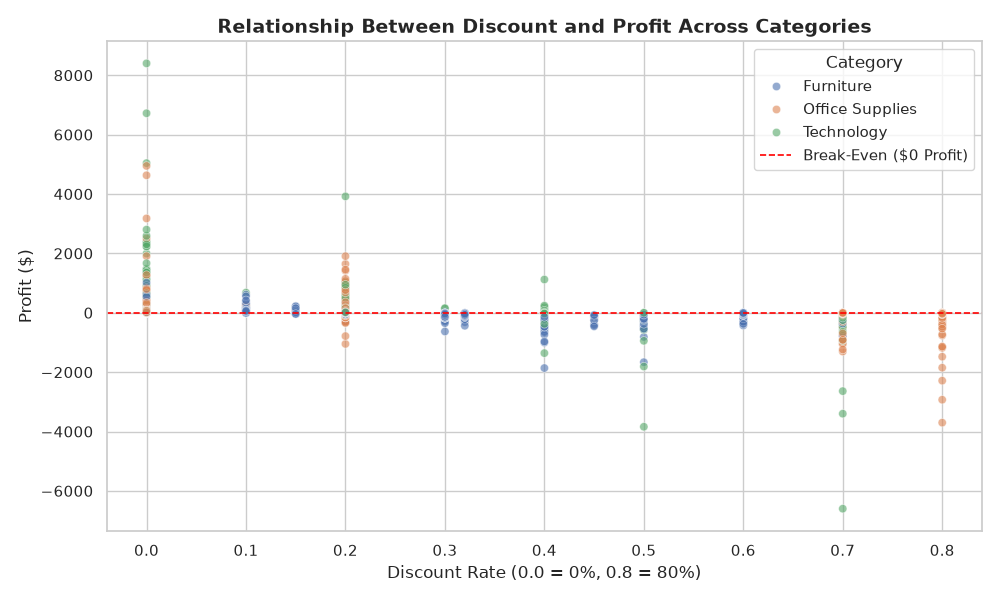

In [9]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Discount',
    y='Profit',
    hue='Category',
    alpha=0.6,
    palette='deep'
)

# Add a horizontal zero-profit reference line
plt.axhline(0, color='red', linestyle='--', linewidth=1.2, label='Break-Even ($0 Profit)')

plt.title('Relationship Between Discount and Profit Across Categories', fontsize=14, fontweight='bold')
plt.xlabel('Discount Rate (0.0 = 0%, 0.8 = 80%)', fontsize=12)
plt.ylabel('Profit ($)', fontsize=12)
plt.legend(title='Category')
plt.tight_layout()
plt.show()


4. Comparative Analysis: Matplotlib vs. Seaborn
Comparison of Insights Gained:
• Macro Trends vs. Item-Level Drivers: The Matplotlib line chart revealed when growth occurred and which broad category drove it (showing Technology surging past $270k in 2017). However, it masked individual product performance. The Seaborn horizontal bar chart filled that gap by exposing that a single item—the Canon imageCLASS 2200 Copier ($61.5k)—accounted for a massive portion of Technology's lead.
• Revenue vs. Profitability Risks: While the line and bar charts focused purely on gross sales volume, the Seaborn scatter plot uncovered a critical business risk that revenue charts hide: high sales do not guarantee profit. Specifically, discounts above 20% consistently turn profitable categories (especially Furniture and Technology) into net losses.
Ease of Use and Effectiveness:
• Matplotlib: Required more manual setup (looping through categories, configuring ax.set_xticks(), and attaching mplcursors for interactivity), but gave exact control over axis formatting and interactive inspection of specific yearly data points.
• Seaborn: Was much faster for multi-dimensional statistical exploration. With just a few lines of code, sns.scatterplot() and sns.catplot() automatically mapped categorical color palettes (hue), handled DataFrame groupings cleanly, and made dense relationships (like the 9,994-row discount-to-profit distribution) immediately readable.